In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pypulseq as pp
import MRzeroCore as mr0
import torchkbnufft as tkbn
import sys
sys.path.insert(0, "..")
from mri import load_brain_phantom, default_system

In [2]:
def build_mpnrage(
    fov: float = 250e-3,
    Nx: int = 128,
    alpha: float = 5.0,
    slice_thickness: float = 3e-3,
    TE: float = 3.98e-3,
    N_readout: int = 300,
    N_segments: int = 20,
    N_dummy: int = 20,
    TI_start: float = 20e-3,
    TD: float = 500e-3,
    rf_spoiling_inc: float = 117.0,
    write_seq: bool = False,
) -> pp.Sequence:
    
    system = default_system()
    seq = pp.Sequence(system)
    deltak = 1 / fov

    rf_inv, gz_inv, _ = pp.make_sinc_pulse(
        flip_angle=np.pi, duration=10e-3, slice_thickness=slice_thickness,
        apodization=0.5, time_bw_product=4, system=system,
        return_gz=True, use='inversion')

    rf, gz, _ = pp.make_sinc_pulse(
        apodization=0.5, duration=2e-3, flip_angle=alpha*np.pi/180,
        slice_thickness=slice_thickness, system=system,
        time_bw_product=4, return_gz=True, use='excitation')

    gx_base = pp.make_trapezoid(channel='x', flat_area=Nx*deltak, flat_time=6.4e-3/5, system=system)
    adc = pp.make_adc(num_samples=Nx, duration=gx_base.flat_time, delay=gx_base.rise_time, system=system)
    gx_pre_base = pp.make_trapezoid(channel='x', area=-gx_base.area/2, duration=2e-3, system=system)
    gz_reph = pp.make_trapezoid(channel='z', area=-gz.area/2, duration=2e-3, system=system)
    gx_spoil_base = pp.make_trapezoid(channel='x', area=0.5*Nx*deltak, system=system)
    gz_spoil = pp.make_trapezoid(channel='z', area=4/slice_thickness, system=system)

    delay_TE = (
        np.ceil((
            TE - pp.calc_duration(gx_pre_base)
            - gz.fall_time - gz.flat_time/2
            - pp.calc_duration(gx_base)/2
        ) / seq.grad_raster_time) * seq.grad_raster_time
    )
    inv_duration   = pp.calc_duration(rf_inv, gz_inv)
    delay_TI_start = (
        np.ceil((TI_start - inv_duration/2 - pp.calc_duration(gz)/2)
                / seq.grad_raster_time) * seq.grad_raster_time
    )
    assert delay_TI_start > 0, 'TI_start too short'

    gre_block_dur = (
        pp.calc_duration(gz) + pp.calc_duration(gx_pre_base)
        + delay_TE + pp.calc_duration(gx_base)
        + pp.calc_duration(gx_spoil_base, gz_spoil)
    )
    delay_TD = np.ceil(TD / seq.grad_raster_time) * seq.grad_raster_time

    total_acquired = N_segments * N_readout
    def spoke_dir(idx):
        phi = np.arccos(1 - 2*(idx+0.5)/total_acquired)
        theta = np.pi*(1+np.sqrt(5))*idx
        return np.sin(phi)*np.cos(theta), np.sin(phi)*np.sin(theta), np.cos(phi)

    rf_phase = 0.0; rf_inc = 0.0; spoke_counter = 0

    for seg in range(N_segments):
        seq.add_block(rf_inv, gz_inv)
        seq.add_block(pp.make_delay(delay_TI_start))

        n_this_seg = N_readout + (N_dummy if seg == 0 else 0)
        for s in range(n_this_seg):
            is_dummy = (seg == 0) and (s < N_dummy)

            rf.phase_offset  = rf_phase / 180 * np.pi
            adc.phase_offset = rf_phase / 180 * np.pi
            rf_inc   = (rf_inc + rf_spoiling_inc) % 360
            rf_phase = (rf_phase + rf_inc) % 360

            kx, ky, kz = (1.0, 0.0, 0.0) if is_dummy else spoke_dir(spoke_counter)
            if not is_dummy:
                spoke_counter += 1

            seq.add_block(rf, gz)
            seq.add_block(
                pp.make_trapezoid(channel='x', area=gx_pre_base.area*kx, duration=2e-3, system=system),
                pp.make_trapezoid(channel='y', area=gx_pre_base.area*ky, duration=2e-3, system=system),
                pp.make_trapezoid(channel='z', area=gx_pre_base.area*kz+gz_reph.area, duration=2e-3, system=system),
            )
            seq.add_block(pp.make_delay(delay_TE))

            gx = pp.make_trapezoid(channel='x', amplitude=gx_base.amplitude*kx,
                        flat_time=gx_base.flat_time, rise_time=gx_base.rise_time, fall_time=gx_base.fall_time, system=system)
            gy = pp.make_trapezoid(channel='y', amplitude=gx_base.amplitude*ky,
                        flat_time=gx_base.flat_time, rise_time=gx_base.rise_time, fall_time=gx_base.fall_time, system=system)
            gz_ro = pp.make_trapezoid(channel='z', amplitude=gx_base.amplitude*kz,
                        flat_time=gx_base.flat_time, rise_time=gx_base.rise_time, fall_time=gx_base.fall_time, system=system)

            if is_dummy: seq.add_block(gx, gy, gz_ro)
            else: seq.add_block(gx, gy, gz_ro, adc)

            seq.add_block(
                pp.make_trapezoid(channel='x', area=gx_spoil_base.area*kx, system=system),
                pp.make_trapezoid(channel='y', area=gx_spoil_base.area*ky, system=system),
                pp.make_trapezoid(channel='z', area=gx_spoil_base.area*kz+gz_spoil.area, system=system),
            )

        seq.add_block(pp.make_delay(delay_TD))

    ok, err = seq.check_timing()
    if ok:
        print('MPnRAGE timing check passed')
        print(f'  GRE block dur : {gre_block_dur*1000:.1f} ms')
        print(f'  Readout train : {N_readout*gre_block_dur*1000:.0f} ms')
        est = N_segments*(inv_duration+delay_TI_start+N_readout*gre_block_dur+TD)
        print(f'  Scan time est : {est/60:.1f} min')
    else: print(f'Timing FAILED: {err}')

    seq.set_definition('FOV',  [fov, fov, slice_thickness])
    seq.set_definition('Name', 'mpnrage_kooshball')
    if write_seq: seq.write('MPnRAGE_Kooshball.seq')
    return seq, gre_block_dur, TI_start


seq, gre_block_dur, TI_start = build_mpnrage(write_seq=True)

/tmp/ipykernel_1211/1790289602.py:20: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf_inv, gz_inv, _ = pp.make_sinc_pulse(
/tmp/ipykernel_1211/1790289602.py:25: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf, gz, _ = pp.make_sinc_pulse(


MPnRAGE timing check passed
  GRE block dur : 7.1 ms
  Readout train : 2133 ms
  Scan time est : 0.9 min


In [3]:
device = torch.device("cuda")
N_readout=300; N_segments=20; Nx=128
Nx_img, Ny_img, Nz_img = Nx, Nx, Nx
fov=250e-3; deltak=1/fov

phantom = load_brain_phantom(
    raw_path='subject04_crisp_v.rawb',
    target_size=(Nx_img,Ny_img,Nz_img), device=device, permute_order=(2,1,0))

signal_raw, _ = mr0.util.simulate('MPnRAGE_Kooshball.seq', phantom)

signal_all = signal_raw.reshape(N_segments, N_readout, Nx)
print(f'signal_all shape: {signal_all.shape}')

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.041375186 s
Compute Graph
Computing Graph: 157.41582 s
Analyze Graph
Analyzing Graph: 4.9073424 s
Converting Rust -> Python: 36.374954 s
<<<< Rust <<<<
signal_all shape: torch.Size([20, 300, 128])


In [4]:
def reconstruct_frame(
    signal_all, seq_file, frame_p, omega,
    N_readout, N_segments, Nx_img, Ny_img, Nz_img, fov, device):

    deltak = 1 / fov
    omega  = min(omega, N_readout - frame_p)

    mr_seq = mr0.Sequence.import_file(seq_file)
    ktraj_full = torch.tensor(mr_seq.get_kspace(), dtype=torch.float32)
    ktraj_full = ktraj_full.reshape(-1, ktraj_full.shape[-1])[:, :3]

    sig_list, ktraj_list = [], []
    for seg in range(N_segments):
        for s_off in range(omega):
            n = frame_p + s_off
            start = (seg * N_readout + n) * Nx_img
            ktraj_list.append(ktraj_full[start : start+Nx_img])
            sig_list.append(signal_all[seg, n, :])

    sig = torch.cat(sig_list, dim=0).to(torch.complex64)
    ktraj = torch.cat(ktraj_list, dim=0)

    ktraj = ktraj / (deltak*Nx_img/2) * np.pi * 0.85
    ktraj = ktraj.clamp(-np.pi, np.pi)
    ktraj = ktraj.T.contiguous().unsqueeze(0).to(device)

    r = torch.linalg.norm(ktraj[0], dim=0)
    dcomp = (r**2).view(1, 1, -1)

    sig = sig.view(1, 1, -1).to(device)
    nufft_ob = tkbn.KbNufftAdjoint(
        im_size=(Nx_img,Ny_img,Nz_img), grid_size=(2*Nx_img,2*Ny_img,2*Nz_img)
    ).to(device)
    image = nufft_ob(sig*dcomp, ktraj)[0, 0]
    return torch.abs(image).cpu().numpy()


def ti_eff(frame_p, omega, TI_start, gre_block_dur):
    return TI_start + (frame_p + (omega-1)/2) * gre_block_dur

In [5]:
omega    = 60
N_frames = N_readout - omega + 1
mid      = Nz_img // 2

images, ti_effs = [], []
for p in range(N_frames):
    img   = reconstruct_frame(signal_all, 'MPnRAGE_Kooshball.seq', frame_p=p, omega=omega,
                               N_readout=N_readout, N_segments=N_segments,
                               Nx_img=Nx_img, Ny_img=Ny_img, Nz_img=Nz_img, fov=fov, device=device)
    ti_ms = ti_eff(p, omega, TI_start, gre_block_dur)*1000
    images.append(np.rot90(img, k=3, axes=(0,1)))
    ti_effs.append(ti_ms)
    if p % 50 == 0: print(f'Frame {p:3d}/{N_frames}  TI_eff={ti_ms:.0f} ms')

print(f'Done -- {len(images)} frames, TI_eff {ti_effs[0]:.0f} -> {ti_effs[-1]:.0f} ms')

/tmp/ipykernel_1211/1733916915.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  ktraj_full = torch.tensor(mr_seq.get_kspace(), dtype=torch.float32)


Frame   0/241  TI_eff=230 ms
Frame  50/241  TI_eff=585 ms
Frame 100/241  TI_eff=941 ms
Frame 150/241  TI_eff=1296 ms
Frame 200/241  TI_eff=1652 ms
Done -- 241 frames, TI_eff 230 -> 1936 ms


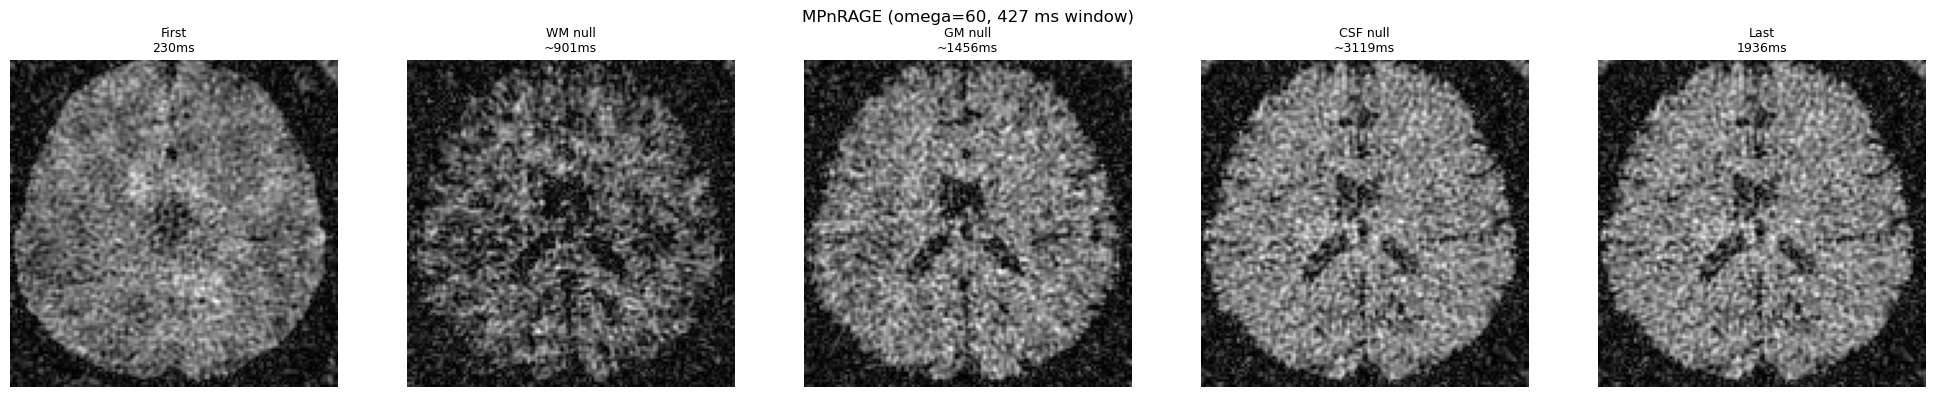

In [6]:
T1_WM=1300e-3; T1_GM=2100e-3; T1_CSF=4500e-3

def find_frame(tgt):
    return int(np.argmin(np.abs(np.array(ti_effs)-tgt)))

frames_to_show = {
    f'First\n{ti_effs[0]:.0f}ms': 0,
    f'WM null\n~{T1_WM*np.log(2)*1000:.0f}ms':  find_frame(T1_WM *np.log(2)*1000),
    f'GM null\n~{T1_GM*np.log(2)*1000:.0f}ms':  find_frame(T1_GM *np.log(2)*1000),
    f'CSF null\n~{T1_CSF*np.log(2)*1000:.0f}ms':find_frame(T1_CSF*np.log(2)*1000),
    f'Last\n{ti_effs[-1]:.0f}ms':               len(images)-1,
}
fig, axes = plt.subplots(1, len(frames_to_show), figsize=(4*len(frames_to_show),4))
for ax,(title,p) in zip(axes, frames_to_show.items()):
    ax.imshow(images[p][:,:,mid], cmap='gray'); ax.set_title(title,fontsize=9); ax.axis('off')
plt.suptitle(f'MPnRAGE (omega={omega}, {omega*gre_block_dur*1000:.0f} ms window)', fontsize=12)
plt.tight_layout(); plt.show()

/tmp/ipykernel_1211/1733916915.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  ktraj_full = torch.tensor(mr_seq.get_kspace(), dtype=torch.float32)


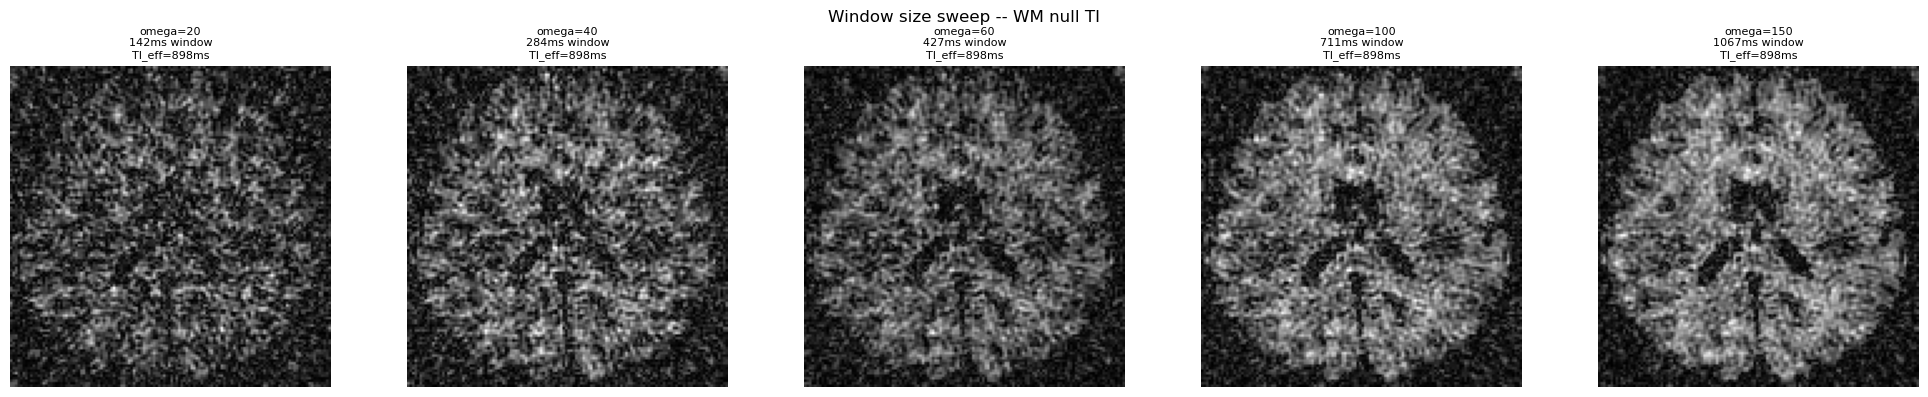

In [7]:
omega_values = [20, 40, 60, 100, 150]
target_ms    = T1_WM * np.log(2) * 1000

fig, axes = plt.subplots(1, len(omega_values), figsize=(4*len(omega_values),4))
for ax, om in zip(axes, omega_values):
    p_best = int(round((target_ms/1000 - TI_start)/gre_block_dur - (om-1)/2))
    p_best = max(0, min(p_best, N_readout-om))
    img_om = reconstruct_frame(signal_all, 'MPnRAGE_Kooshball.seq', frame_p=p_best, omega=om,
                                N_readout=N_readout, N_segments=N_segments,
                                Nx_img=Nx_img, Ny_img=Ny_img, Nz_img=Nz_img, fov=fov, device=device)
    img_om  = np.rot90(img_om, k=3, axes=(0,1))
    ti_this = ti_eff(p_best, om, TI_start, gre_block_dur)*1000
    ax.imshow(img_om[:,:,mid], cmap='gray')
    ax.set_title(f'omega={om}\n{om*gre_block_dur*1000:.0f}ms window\nTI_eff={ti_this:.0f}ms', fontsize=8)
    ax.axis('off')
plt.suptitle('Window size sweep -- WM null TI', fontsize=12)
plt.tight_layout(); plt.show()

/tmp/ipykernel_1211/1932148304.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  signal_magnitude = np.abs(center_k)


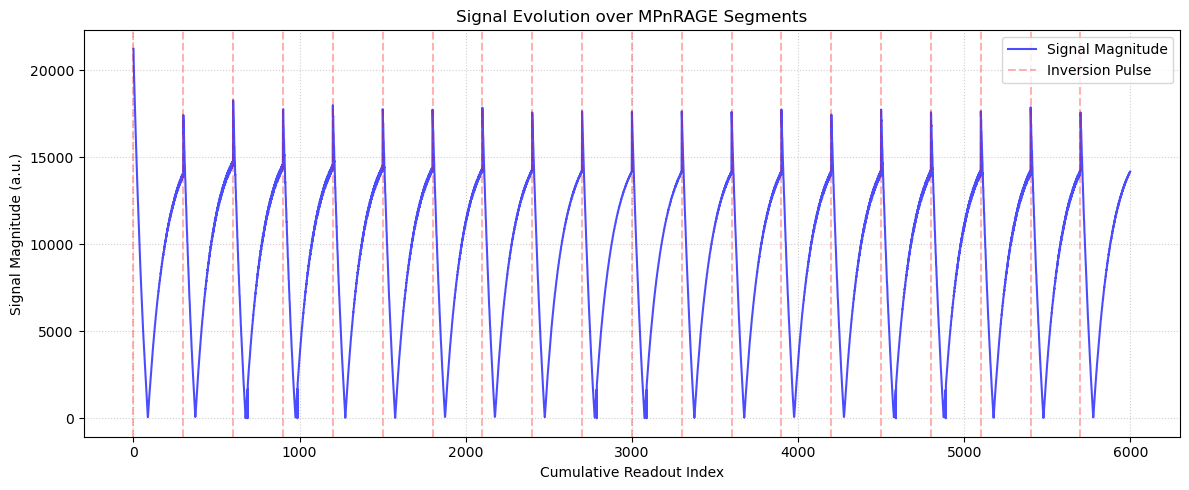

In [8]:
center_k = signal_all[:, :, Nx // 2]
signal_magnitude = np.abs(center_k)

plt.figure(figsize=(12, 5))
plt.plot(signal_magnitude.flatten(), label='Signal Magnitude', color='blue', alpha=0.7)

segment_starts = np.arange(0, N_segments * N_readout, N_readout)
for start in segment_starts:
    plt.axvline(x=start, color='red', linestyle='--', alpha=0.3, label='Inversion Pulse' if start == 0 else "")

plt.title('Signal Evolution over MPnRAGE Segments')
plt.xlabel('Cumulative Readout Index')
plt.ylabel('Signal Magnitude (a.u.)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()